# Résolution exacte du CVRP : PLNE et Branch and Bound

**Projet CesiCDP — partie méthode exacte.**

Les métaheuristiques du projet (Hill Climbing, algorithme génétique, recherche tabou) donnent de bonnes tournées rapidement, mais sans garantie : on ne sait pas à quelle distance de l'optimum elles se trouvent. Une méthode exacte apporte cette garantie. Elle fournit :

- **la solution optimale** sur les petites instances, qui sert de référence pour mesurer le gap des métaheuristiques ;
- **une borne inférieure** sur les instances plus grandes : même sans optimum, on sait qu'aucune solution ne peut coûter moins.

Ce notebook présente notre résolution du PLNE par **Branch and Bound**, implémentée dans `algorithms/plne.py`, puis étudie expérimentalement jusqu'où elle permet d'aller.

**Plan**
1. Le modèle PLNE (et une correction du Livrable 1)
2. L'algorithme de Branch and Bound
3. Démonstration sur des instances VRPLIB
4. Validation de l'implémentation
5. Étude expérimentale
6. Bilan, limites et pistes d'amélioration

> L'exécution complète du notebook prend environ 15 minutes, surtout à cause des comparaisons avec CBC limitées à 60 s par instance.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from algorithms.plne import branch_and_bound, build_model, clarke_wright, solve_with_cbc
from common import (Instance, check_solution, gap, load_instance, plot_solution,
                    random_instance, solution_cost, sub_instance)

pd.set_option("display.precision", 2)
DATA = Path("data")

## 1. Le modèle PLNE

### 1.1 Deux formulations

Le module sait construire deux PLNE équivalents (mêmes solutions entières, même optimum) :

| | `vehicle_index` (Livrable 1) | `two_index` (utilisée par défaut) |
|---|---|---|
| Variables | $x_{ijk}$, $y_{ik}$, $z_k$, $u_{ik}$ | $x_{ij}$, $u_i$ |
| Idée | on sait quel camion emprunte chaque arc | on sait seulement quels arcs sont utilisés |
| Taille | $\approx m\,n^2$ variables | $\approx n^2$ variables |
| Symétrie | échanger deux camions donne la même solution : $m!$ copies de chaque solution | aucune |

Comme les camions sont identiques, savoir *lequel* fait une tournée n'apporte rien. Pire, la symétrie multiplie le nombre de nœuds que le Branch and Bound doit explorer. On utilise donc par défaut la **formulation à deux indices** :

$$\min \sum_{(i,j)} c_{ij}\,x_{ij}$$

sous les contraintes

- $\sum_{j} x_{ij} = 1$ et $\sum_{j} x_{ji} = 1$ pour chaque client $i$ : une entrée et une sortie ;
- $\lceil \sum_i q_i / Q \rceil \le \sum_j x_{0j} \le m$ : entre le minimum de camions nécessaire et la flotte disponible ;
- $u_i - u_j + Q\,x_{ij} + (Q - q_i - q_j)\,x_{ji} \le Q - q_j$ pour deux clients $i \ne j$ : la charge cumulée $u$ augmente le long d'une tournée (contrainte de Miller-Tucker-Zemlin *relevée* [3, 4]). Elle impose la capacité et interdit les sous-tours ;
- $q_i \le u_i \le Q$, plus quelques inégalités valides qui resserrent ces bornes ;
- $x_{ij} \in \{0,1\}$. Les arcs $i \to j$ tels que $q_i + q_j > Q$ sont supprimés d'office.

In [2]:
inst = load_instance(DATA / "E-n13-k4.vrp")
sizes = []
for formulation in ["two_index", "vehicle_index"]:
    model = build_model(inst, formulation)
    sizes.append({"formulation": formulation, "variables": model.n_vars,
                  "contraintes": model.n_constraints})
pd.DataFrame(sizes).set_index("formulation")

,variables,contraintes
formulation,,
two_index,168,194
vehicle_index,724,792


### 1.2 Une correction du Livrable 1 : la contrainte F interdisait les camions pleins

Dans le Livrable 1, la progression de la charge s'écrit

$$u_{jk} \ge u_{ik} + q_j - Q(1 - x_{ijk}).$$

Si l'arc $i \to j$ n'est pas emprunté par le camion $k$ ($x_{ijk} = 0$) **et** que le client $j$ n'est pas dans ce camion ($u_{jk} = 0$), elle devient $0 \ge u_{ik} + q_j - Q$, c'est-à-dire $u_{ik} \le Q - q_j$. Un camion dont la charge cumulée dépasse $Q - q_j$ est donc interdit dès qu'un client $j$ est servi par un autre camion. En particulier, **un camion plein n'est jamais accepté**, et l'optimum peut être éliminé.

La correction consiste à ne compter $q_j$ que si $j$ est dans le camion $k$ :

$$u_{jk} \ge u_{ik} + q_j\,y_{jk} - Q(1 - x_{ijk}).$$

Vérification sur un petit exemple : 3 clients de demande 5, des camions de capacité 10 et 2 camions. Toute solution a forcément un camion plein.

In [3]:
coords = np.array([[0, 0], [10, 0], [0, 10], [10, 10]], dtype=float)
diff = coords[:, None] - coords[None, :]
full_truck = Instance(name="camion-plein", distances=np.floor(np.sqrt((diff**2).sum(axis=2)) + 0.5),
                      demands=np.array([0, 5, 5, 5]), capacity=10, n_vehicles=2, coords=coords)

for formulation in ["vehicle_index_original", "vehicle_index"]:
    res = solve_with_cbc(full_truck, formulation=formulation)
    print(f"{formulation:24s} -> {res.status:10s} coût {res.cost:g}  tournées {res.routes}")

vehicle_index_original   -> infeasible coût inf  tournées []


vehicle_index            -> optimal    coût 54  tournées [[3, 2], [1]]


Le modèle d'origine est déclaré **infaisable** alors qu'une solution évidente existe. Le modèle corrigé la trouve. C'est la version corrigée qui est implémentée (`formulation="vehicle_index"`) et qui devra figurer dans le livrable final.

## 2. L'algorithme de Branch and Bound

Le Branch and Bound [1] explore un arbre de sous-problèmes. Chaque nœud correspond au PLNE dans lequel certaines variables $x_{ij}$ ont été fixées à 0 ou à 1.

**Borne inférieure (LB).** En chaque nœud, on résout la **relaxation linéaire** : les variables binaires deviennent continues dans $[0, 1]$. Son optimum est inférieur ou égal à celui de toute solution entière du nœud. Les relaxations sont résolues par le solveur HiGHS [8]. Il repart de la solution du nœud précédent (démarrage à chaud), ce qui rend chaque nœud environ dix fois plus rapide qu'une résolution depuis zéro.

**Borne supérieure (UB).** C'est le coût de la meilleure solution réalisable connue. Elle est initialisée par l'heuristique des économies de Clarke & Wright [2], suivie d'un 2-opt. On peut aussi fournir la solution d'une métaheuristique (`initial_routes=...`).

**Élagage.** Un nœud est abandonné dans trois cas :
1. sa relaxation est **infaisable** ;
2. sa borne est $\ge$ UB : il ne peut pas contenir mieux que ce qu'on a déjà. Les coûts étant entiers, on compare $\lceil LB \rceil$ à UB ;
3. sa solution est **entière** : c'est une tournée réalisable, qui devient la nouvelle UB si elle est meilleure.

**Séparation (branching).** Sinon, on choisit la variable la plus fractionnaire (valeur la plus proche de 0,5) et on crée deux fils, $x_{ij} = 0$ et $x_{ij} = 1$.

**Exploration.** Par défaut, on traite d'abord le nœud de plus petite borne (*best-first*), ce qui fait monter la borne inférieure globale le plus vite. L'option `strategy="depth_first"` plonge en profondeur.

**Coupes de capacité (option `cuts=True`, activée par défaut).** La relaxation de la formulation MTZ est faible : elle laisse un écart important avec l'optimum, et l'arbre devient énorme. On la renforce avec les *coupes de capacité arrondies* [5, 6] : un ensemble $S$ de clients demande au moins $r(S) = \lceil q(S)/Q \rceil$ camions, donc au plus $|S| - r(S)$ arcs relient deux clients de $S$ :

$$\sum_{i, j \in S} x_{ij} \le |S| - \left\lceil \frac{\sum_{i \in S} q_i}{Q} \right\rceil.$$

Toute solution entière respecte ces inégalités, mais pas forcément la solution fractionnaire. Une heuristique gloutonne cherche des ensembles $S$ qui les violent : on part d'un client, puis on ajoute le client le plus « relié » à $S$ dans la relaxation. On ajoute les coupes trouvées et on résout à nouveau, jusqu'à 50 tours à la racine et 2 dans les autres nœuds. Avec ces coupes, la méthode devient un *Branch and Cut*. `cuts=False` redonne le Branch and Bound pur.

**Résultat.** La fonction renvoie la meilleure solution, la borne inférieure prouvée et un statut. `optimal` signifie que l'arbre a été entièrement exploré, donc LB = UB. Sinon, le gap $100\,(UB - LB)/LB$ majore l'écart à l'optimum.

## 3. Démonstration

### 3.1 E-n13-k4 (12 clients, 4 camions, optimum connu : 247)

In [4]:
inst = load_instance(DATA / "E-n13-k4.vrp")
print(inst)
cw = clarke_wright(inst)
print("Clarke & Wright :", solution_cost(inst, cw), cw)
res = branch_and_bound(inst, time_limit=60, verbose=True)
print("Tournées optimales :", res.routes)
print("Contraintes violées :", check_solution(inst, res.routes) or "aucune")

Instance('E-n13-k4', clients=12, Q=6000, m=4, best_known=247.0)
Clarke & Wright : 275.0 [[1], [10, 5, 7, 4], [8, 11, 3], [6, 9, 12, 2]]


E-n13-k4 | branch_and_bound (two_index) | optimal | coût 247 | borne inf. 247 | gap 0.00 % | 17 nœuds | 0.65 s
Tournées optimales : [[1], [2, 7, 4, 11], [3, 5, 8], [9, 12, 10, 6]]
Contraintes violées : aucune


Partant de la solution de Clarke & Wright (275), le Branch and Bound trouve et **prouve** l'optimum 247, qui est la valeur connue dans la littérature.

### 3.2 P-n16-k8 (15 clients, 8 camions, capacité très serrée)

Ici la demande totale remplit presque les 8 camions. Clarke & Wright utilise 9 tournées et ne fournit donc pas de solution de départ : le Branch and Bound part sans borne supérieure.

P-n16-k8 | branch_and_bound (two_index) | optimal | coût 450 | borne inf. 450 | gap 0.00 % | 209 nœuds | 3.32 s


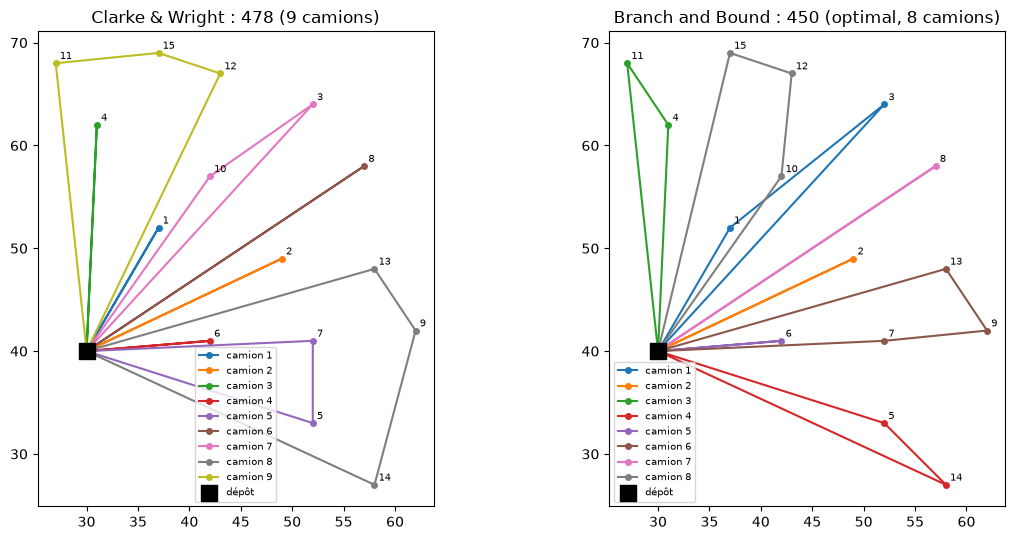

In [5]:
inst = load_instance(DATA / "P-n16-k8.vrp")
cw = clarke_wright(inst)
res = branch_and_bound(inst, time_limit=60)
print(res.summary())

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
plot_solution(inst, cw, ax=axes[0], title=f"Clarke & Wright : {solution_cost(inst, cw):g} ({len(cw)} camions)")
plot_solution(inst, res.routes, ax=axes[1], title=f"Branch and Bound : {res.cost:g} (optimal, {len(res.routes)} camions)")
plt.tight_layout()
plt.show()

## 4. Validation de l'implémentation

Un algorithme exact doit être vérifié avec soin : une erreur dans l'élagage peut faire « prouver » un faux optimum. On le compare à deux références indépendantes.

1. **Force brute** sur des instances de 6 clients : on énumère les $6! = 720$ ordres de visite et on découpe chacun au mieux en tournées. Cette méthode n'utilise pas du tout le PLNE.
2. **CBC** (via PuLP), un solveur reconnu, sur exactement le même PLNE.

Chaque solution est aussi vérifiée par `check_solution` : chaque client est servi une fois, la capacité est respectée et la flotte n'est pas dépassée.

In [6]:
from tests.test_plne import brute_force

rows = []
for seed in range(5):
    inst = random_instance(6, capacity=50, demand_range=(8, 25), seed=seed)
    bb = branch_and_bound(inst)
    rows.append({"instance": inst.name, "force brute": brute_force(inst), "B&B": bb.cost,
                 "réalisable": not check_solution(inst, bb.routes)})
for seed in range(5):
    inst = random_instance(10, capacity=60, demand_range=(5, 25), seed=100 + seed)
    bb, cbc = branch_and_bound(inst), solve_with_cbc(inst)
    rows.append({"instance": inst.name, "CBC": cbc.cost, "B&B": bb.cost,
                 "réalisable": not check_solution(inst, bb.routes)})
validation = pd.DataFrame(rows).set_index("instance")
validation[["force brute", "CBC", "B&B", "réalisable"]]

,force brute,CBC,B&B,réalisable
instance,,,,
random-n6-s0,345.0,NaN,345.0,True
random-n6-s1,348.0,NaN,348.0,True
random-n6-s2,323.0,NaN,323.0,True
random-n6-s3,258.0,NaN,258.0,True
random-n6-s4,335.0,NaN,335.0,True
random-n10-s100,NaN,469.0,469.0,True
random-n10-s101,NaN,360.0,360.0,True
random-n10-s102,NaN,447.0,447.0,True
random-n10-s103,NaN,358.0,358.0,True


Le Branch and Bound retrouve exactement l'optimum de la force brute et de CBC sur les 10 instances, et toutes ses solutions sont réalisables. Les mêmes vérifications sont automatisées dans `tests/test_plne.py`.

## 5. Étude expérimentale

Le Branch and Bound est déterministe : il explore toujours le même arbre sur la même instance, donc une seule exécution par instance suffit (contrairement aux métaheuristiques). Le **nombre de nœuds** est donc reproductible. Les **temps**, eux, varient d'une exécution à l'autre selon la charge de la machine, et ce qui est atteint avant une limite de temps peut varier aussi.

### 5.1 Effet des coupes de capacité

On compare le Branch and Bound pur (`cuts=False`) et avec coupes, sur des sous-instances d'A-n32-k5 (les $n$ premiers clients), avec 30 s maximum par résolution.

In [7]:
A = load_instance(DATA / "A-n32-k5.vrp")
rows = []
for n in [8, 10, 12, 14, 16]:
    inst = sub_instance(A, n)
    for cuts in [False, True]:
        r = branch_and_bound(inst, time_limit=30, cuts=cuts)
        rows.append({"n": n, "coupes": cuts, "statut": r.status, "coût": r.cost,
                     "borne inf.": r.lower_bound, "gap (%)": r.gap,
                     "borne racine": r.root_bound, "nœuds": r.nodes, "temps (s)": r.time})
cuts_df = pd.DataFrame(rows)
cuts_df.pivot(index="n", columns="coupes", values=["nœuds", "temps (s)", "borne racine", "gap (%)"])

nœuds       temps (s)       borne racine        gap (%)      
coupes   False True      False True         False  True    False True 
n                                                                     
8         65.0   1.0      0.34  0.06        320.0  338.0    0.00   0.0
10        13.0   1.0      0.12  0.04        360.0  362.0    0.00   0.0
12      5371.0   1.0     16.96  0.03        352.0  416.0    0.00   0.0
14      7183.0   1.0     30.00  0.10        374.0  431.0    1.65   0.0
16      9015.0   7.0     30.01  0.06        421.0  509.0    9.38   0.0

Les coupes relèvent fortement la borne à la racine : elles éliminent la plupart des solutions fractionnaires « trop optimistes » de la formulation MTZ. Avec coupes, l'arbre se réduit ici à une poignée de nœuds. Sans coupes, le nombre de nœuds se compte en milliers dès 12 clients, et sur les plus grandes sous-instances les 30 s ne suffisent plus à prouver l'optimum (gap non nul). Chaque nœud coûte un peu plus cher avec les coupes (recherche de coupes, LP plus gros), mais le gain sur le nombre de nœuds compense très largement.

### 5.2 Formulation à deux indices ou indexée par véhicule

Pour comparer les formulations elles-mêmes, on les met à armes égales : **Branch and Bound pur, sans coupes**, sur de petites instances aléatoires (3 camions, 30 s maximum). Avec les coupes, ces instances sont si petites que les deux formulations se résolvent dès la racine.

In [8]:
rows = []
for n in [5, 6, 7, 8]:
    inst = random_instance(n, capacity=40, demand_range=(8, 20), n_vehicles=3, seed=n)
    for formulation in ["two_index", "vehicle_index"]:
        r = branch_and_bound(inst, formulation=formulation, time_limit=30, cuts=False)
        rows.append({"n": n, "formulation": formulation, "variables": r.n_vars, "statut": r.status,
                     "coût": r.cost, "relaxation racine": r.root_lp_bound, "nœuds": r.nodes,
                     "temps (s)": r.time})
pd.DataFrame(rows).pivot(index="n", columns="formulation",
                         values=["variables", "statut", "coût", "relaxation racine", "nœuds", "temps (s)"])

variables                  statut                    coût  \
formulation two_index vehicle_index two_index vehicle_index two_index   
n                                                                       
5                  35           123   optimal       optimal     259.0   
6                  48           165   optimal       optimal     259.0   
7                  63           213   optimal       optimal     385.0   
8                  80           267   optimal    time_limit     378.0   

                          relaxation racine                   nœuds  \
formulation vehicle_index         two_index vehicle_index two_index   
n                                                                     
5                   259.0             259.0         196.8         1   
6                   259.0             259.0        219.95         1   
7                   385.0             363.0        292.22       113   
8                   378.0            275.94        239.92      1175   

                          temps (s)                
formulation vehicle_index two_index vehicle_index  
n                                                  
5                     421       0.0          0.57  
6                     593      0.01          1.59  
7                    4373      0.06         13.74  
8                    7069      1.73         30.02

Les deux formulations trouvent le même optimum quand elles terminent. Mais la formulation indexée par véhicule a plus de trois fois plus de variables et une relaxation linéaire nettement plus faible (colonne « relaxation racine »). Elle a aussi une symétrie entre camions : l'arbre doit explorer plusieurs fois la même solution, avec les camions numérotés autrement. Son nombre de nœuds est donc bien plus élevé, et il grandit beaucoup plus vite avec $n$. Le modèle du Livrable 1 reste utile pour expliquer le problème, mais il n'est pas adapté à la résolution.

### 5.3 Évolution avec la taille de l'instance

On résout les sous-instances d'A-n32-k5 et de B-n31-k5 de 10 à 31 clients (60 s maximum). On compare à CBC sur le même PLNE, avec la même limite de temps.

In [9]:
B = load_instance(DATA / "B-n31-k5.vrp")
rows = []
for base in [A, B]:
    for n in [10, 15, 20, 25, base.n_customers]:
        inst = base if n == base.n_customers else sub_instance(base, n)
        for method in ["B&B", "CBC"]:
            r = branch_and_bound(inst, time_limit=60) if method == "B&B" else solve_with_cbc(inst, time_limit=60)
            rows.append({"famille": base.name, "n": n, "méthode": method, "statut": r.status,
                         "coût": r.cost, "borne inf.": r.lower_bound, "gap (%)": r.gap,
                         "nœuds": r.nodes, "temps (s)": r.time})
size_df = pd.DataFrame(rows)
Path("results").mkdir(exist_ok=True)
size_df.to_csv("results/plne_scaling.csv", index=False)
size_df.pivot_table(index=["famille", "n"], columns="méthode", values=["temps (s)", "gap (%)"], aggfunc="first")

gap (%)        temps (s)       
méthode         B&B    CBC       B&B    CBC
famille  n                                 
A-n32-k5 10    0.00   0.00      0.04   0.44
         15    0.00   0.00      0.16   8.16
         20    0.00  38.76      0.29  61.05
         25    0.00  62.42     39.31  61.02
         31    0.26  84.90     60.11  60.64
B-n31-k5 10    0.00   0.00      0.03   1.53
         15    0.00   0.00      0.10  50.86
         20    0.00  18.45      0.40  60.99
         25    0.00  26.64     14.31  60.83
         30    0.00    inf     15.02  61.37

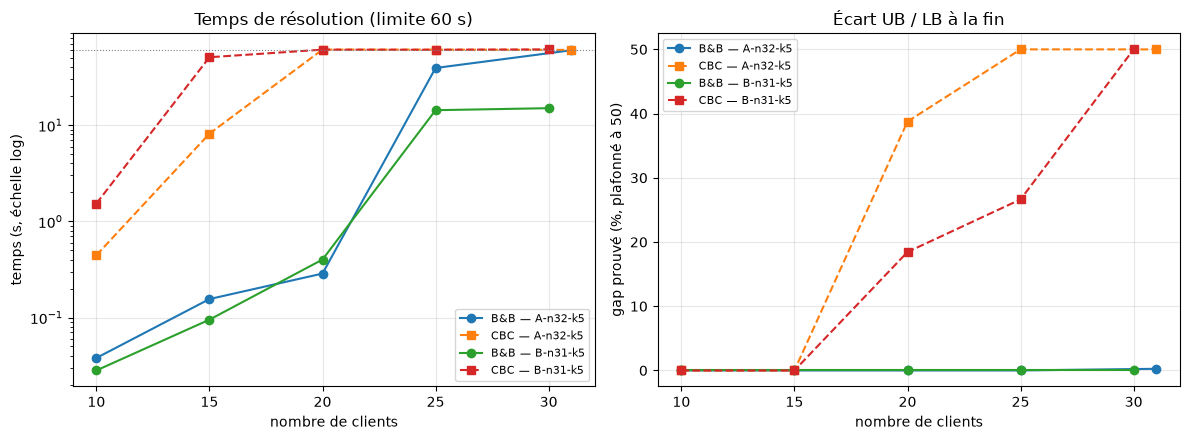

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for (family, method), group in size_df.groupby(["famille", "méthode"]):
    style = "-o" if method == "B&B" else "--s"
    axes[0].plot(group["n"], group["temps (s)"], style, label=f"{method} — {family}")
    axes[1].plot(group["n"], group["gap (%)"].clip(upper=50), style, label=f"{method} — {family}")
axes[0].set_yscale("log")
axes[0].axhline(60, color="grey", lw=0.8, ls=":")
axes[0].set(xlabel="nombre de clients", ylabel="temps (s, échelle log)", title="Temps de résolution (limite 60 s)")
axes[1].set(xlabel="nombre de clients", ylabel="gap prouvé (%, plafonné à 50)", title="Écart UB / LB à la fin")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

Le temps de calcul croît très vite avec le nombre de clients, comme on l'attend pour un problème NP-difficile. Il dépend aussi beaucoup de la structure de l'instance : l'instance A-n32-k5 complète (31 clients) n'est pas résolue en 60 s, alors que B-n31-k5 complète (30 clients) l'est bien avant la limite. Le nombre de nœuds n'augmente même pas toujours avec $n$ : sur la famille B, il faut 269 nœuds pour 25 clients et seulement 123 pour 30 (détails dans `results/plne_scaling.csv`). Notre Branch and Bound va beaucoup plus loin que CBC sur ce modèle. Ce n'est pas que notre code soit plus rapide que CBC, c'est qu'il utilise les coupes de capacité : CBC ne connaît pas ces inégalités propres au CVRP. Il doit se contenter de la relaxation MTZ, laisse des écarts importants dès 20 clients, et ne trouve parfois même aucune solution en 60 s (gap infini).

### 5.4 Convergence des bornes sur A-n32-k5 (31 clients)

A-n32-k5 est la plus difficile de nos instances. On laisse jusqu'à 300 s au Branch and Bound (il lui en faut un peu plus d'une minute sur une machine non chargée) et on suit l'évolution des deux bornes.

A-n32-k5 | branch_and_bound (two_index) | optimal | coût 784 | borne inf. 784 | gap 0.00 % | 1345 nœuds | 95.48 s | optimum connu : 784
Meilleure solution trouvée à 46.7 s ; optimalité prouvée à 95.5 s.


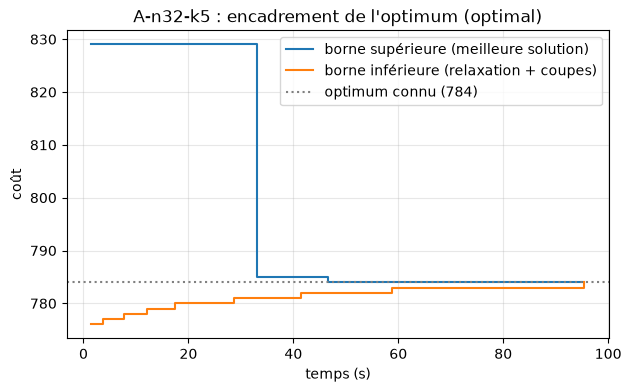

In [11]:
res_a = branch_and_bound(A, time_limit=300)
print(res_a.summary(), f"| optimum connu : {A.best_known:g}")
t, _, lb, ub = zip(*res_a.history)
found = next(time_ for time_, _, _, cost in res_a.history if cost == res_a.cost)
end = "optimalité prouvée" if res_a.status == "optimal" else "arrêt sans preuve complète"
print(f"Meilleure solution trouvée à {found:.1f} s ; {end} à {res_a.time:.1f} s.")
plt.figure(figsize=(7, 4))
plt.step(t, ub, where="post", label="borne supérieure (meilleure solution)")
plt.step(t, lb, where="post", label="borne inférieure (relaxation + coupes)")
plt.axhline(A.best_known, color="grey", ls=":", label=f"optimum connu ({A.best_known:g})")
plt.xlabel("temps (s)")
plt.ylabel("coût")
plt.title(f"A-n32-k5 : encadrement de l'optimum ({res_a.status})")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

La borne inférieure monte d'abord très vite (coupes à la racine), puis lentement : chaque point gagné demande d'explorer de nombreux nœuds. La meilleure solution, elle, est souvent trouvée bien avant la fin. **Trouver une très bonne solution est relativement rapide ; prouver qu'on ne peut pas faire mieux est ce qui coûte cher.** Si on arrête plus tôt, l'encadrement entre les deux bornes reste exploitable : c'est ce qui permet de mesurer un gap sur des instances que l'on ne sait pas résoudre complètement.

### 5.5 Stratégie d'exploration

On compare *best-first* et *depth-first*, avec et sans coupes.

In [12]:
rows = []
for inst in [load_instance(DATA / "E-n13-k4.vrp"), sub_instance(A, 12)]:
    for cuts in [True, False]:
        for strategy in ["best_first", "depth_first"]:
            r = branch_and_bound(inst, strategy=strategy, cuts=cuts, time_limit=60)
            rows.append({"instance": inst.name, "coupes": cuts, "stratégie": strategy, "statut": r.status,
                         "coût": r.cost, "nœuds": r.nodes, "temps (s)": r.time})
pd.DataFrame(rows).set_index(["instance", "coupes", "stratégie"])

statut   coût  nœuds  temps (s)
instance      coupes stratégie                                    
E-n13-k4      True   best_first   optimal  247.0     17       0.34
                     depth_first  optimal  247.0     19       0.35
              False  best_first   optimal  247.0   3673       7.99
                     depth_first  optimal  247.0   4975      10.04
A-n32-k5[:12] True   best_first   optimal  416.0      1       0.06
                     depth_first  optimal  416.0      1       0.08
              False  best_first   optimal  416.0   5371      12.60
                     depth_first  optimal  416.0   5903      17.03

Avec les coupes, l'arbre est si petit que la stratégie ne change presque rien. Sans coupes, le *best-first* évalue moins de nœuds : il ne développe jamais un nœud dont la borne dépasse l'optimum. Le *depth-first* a d'autres atouts : il consomme moins de mémoire (peu de nœuds en attente) et trouve plus vite des solutions entières, ce qui est utile quand on part sans borne supérieure. Côté temps, les écarts entre les deux stratégies sont du même ordre que les variations d'une exécution à l'autre : on ne peut pas conclure sur ce point. Comme Clarke & Wright fournit déjà une bonne solution de départ et que la borne inférieure globale est directement lisible en *best-first*, c'est notre choix par défaut.

## 6. Bilan, limites et pistes d'amélioration

**Ce que la méthode exacte apporte au projet**
- Des **optimums prouvés** jusqu'à une trentaine de clients : E-n13-k4 (247), P-n16-k8 (450), B-n31-k5 (672) et A-n32-k5 (784), conformes aux valeurs de la littérature. Ils servent à valider les métaheuristiques et à calculer leur gap exact.
- Des **bornes inférieures** sur les instances non résolues : le gap $100\,(\text{coût} - LB)/LB$ majore le vrai gap d'une métaheuristique, même sans optimum connu.
- Une **correction du modèle du Livrable 1** (contrainte F), mise en évidence par l'implémentation.

**Limites**
- Le temps de calcul croît exponentiellement avec la taille. Au-delà de quelques dizaines de clients, la méthode exacte ne termine plus : pour les instances de plusieurs milliers de villes de l'énoncé, les métaheuristiques sont indispensables.
- Les performances dépendent fortement de l'instance (répartition des clients, capacité plus ou moins serrée).
- La recherche de coupes est heuristique : elle peut manquer des inégalités violées.

**Pistes d'amélioration**
- Séparation plus complète des coupes de capacité (bibliothèque CVRPSEP [6]) et autres familles de coupes (comb, multistar).
- Meilleure règle de branchement (*strong branching*, pseudo-coûts) au lieu de la variable la plus fractionnaire.
- Démarrer avec la solution de la meilleure métaheuristique (`initial_routes=`) : une meilleure borne supérieure élague davantage.
- Pour aller beaucoup plus loin : formulation par ensembles de tournées et génération de colonnes (*Branch-Cut-and-Price*), l'état de l'art pour le CVRP [7].

## Références

1. A. H. Land, A. G. Doig, *An automatic method of solving discrete programming problems*, Econometrica 28(3), 1960. **Principe du Branch and Bound.**
2. G. Clarke, J. W. Wright, *Scheduling of vehicles from a central depot to a number of delivery points*, Operations Research 12(4), 1964. **Heuristique des économies.**
3. M. Desrochers, G. Laporte, *Improvements and extensions to the Miller-Tucker-Zemlin subtour elimination constraints*, Operations Research Letters 10(1), 1991. **Contraintes MTZ relevées.**
4. I. Kara, G. Laporte, T. Bektas, *A note on the lifted Miller–Tucker–Zemlin subtour elimination constraints for the capacitated vehicle routing problem*, European Journal of Operational Research 158(3), 2004. **MTZ relevées pour le CVRP.**
5. P. Augerat, J. M. Belenguer, E. Benavent, A. Corberán, D. Naddef, G. Rinaldi, *Computational results with a branch and cut code for the capacitated vehicle routing problem*, rapport de recherche 949-M, Université Joseph Fourier, Grenoble, 1995. **Coupes de capacité ; instances A, B et P.**
6. J. Lysgaard, A. N. Letchford, R. W. Eglese, *A new branch-and-cut algorithm for the capacitated vehicle routing problem*, Mathematical Programming 100(2), 2004. **Séparation des coupes (CVRPSEP).**
7. P. Toth, D. Vigo (dir.), *Vehicle Routing: Problems, Methods, and Applications*, 2e éd., SIAM, 2014. **Ouvrage de référence sur le VRP.**
8. Q. Huangfu, J. A. J. Hall, *Parallelizing the dual revised simplex method*, Mathematical Programming Computation 10, 2018. **Solveur HiGHS.**